# Wav3 GPL contours and measurements

Recording: `SOCAL_H_76_230427_014845.x.wav` (wav3), processed with the updated `GPL_Python` contour stack.

Outputs under `/home/yfreund/whale_processing/LeiData/GPL_Python_outputs_wav3_contours/`:
- `Detections_*.npy` — sparse islands (`cm`, `cm_max`) + measurements
- `CSV_*.csv` — flat measurement table
- `spectrogram_npy/` — whitened windows

Spectrograms use **jet** and the **full data range** of the plotted patch.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

# Repo root must be on sys.path so `import analysis` works when the kernel
# cwd is this notebooks/ folder (pytest sets pythonpath; Jupyter does not).
REPO_ROOT = Path("../../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.GPL_Python.gpl_contour import from_sparse
from analysis.GPL_Python.gpl_outputs import load_detections_npy

OUT = Path("/home/yfreund/whale_processing/LeiData/GPL_Python_outputs_wav3_contours")
STEM = "SOCAL_H_76_230427_014845.x"
DET_PATH = OUT / f"Detections_{STEM}.npy"
CSV_PATH = OUT / f"CSV_{STEM}.csv"
NPY_DIR = OUT / "spectrogram_npy"

plt.rcParams["figure.dpi"] = 120
print("REPO_ROOT", REPO_ROOT)

REPO_ROOT /home/yfreund/projects/panMP_whales


In [2]:
det = load_detections_npy(DET_PATH)
calls = det["calls"]
csv = pd.read_csv(CSV_PATH)

sidecars = sorted(NPY_DIR.glob(f"spwhiten_{STEM}_w*.json"))
windows = []
for sc in sidecars:
    meta = json.loads(sc.read_text())
    windows.append(
        {
            "meta": meta,
            "path": NPY_DIR / f"{sc.stem}.npy",
            "start_sample": int(meta["start_sample"]),
            "end_sample": int(meta["end_sample"]),
            "hop": int(meta["overlap"]),
            "sample_freq": float(meta["sample_freq"]),
            "freq_lo": float(meta["start_freq"]),
            "freq_hi": float(meta["end_freq"]),
        }
    )

print(f"detections: {len(calls)}  windows: {len(windows)}  CSV rows: {len(csv)}")
csv[["start_time", "end_time", "cm_duration_sec", "cm_slope", "cm_start_freq_hz", "cm_end_freq_hz", "cm_freq_bandwidth_hz"]].describe()

detections: 644  windows: 30  CSV rows: 644


,start_time,end_time,cm_duration_sec,cm_slope,cm_start_freq_hz,cm_end_freq_hz,cm_freq_bandwidth_hz
count,6.440000e+02,6.440000e+02,644.000000,579.000000,579.000000,579.000000,644.000000
mean,2.230187e+08,2.233613e+08,1.198271,-14.853830,1600.121884,1642.492127,808.621045
std,1.321823e+08,1.321911e+08,1.111229,1915.642574,1743.432079,1707.540561,1540.442858
min,1.000000e+00,8.355840e+05,0.000000,-10599.313287,83.449219,77.345703,0.000000
25%,1.095527e+08,1.099521e+08,0.491520,-197.993574,272.658203,318.434570,109.863281
50%,2.130351e+08,2.135389e+08,0.860160,8.449014,611.403320,644.972656,231.933594
75%,3.455591e+08,3.471197e+08,1.720320,334.436818,2979.262207,3000.929688,573.730469
max,4.488117e+08,4.499668e+08,7.249920,12149.905697,7001.882623,7086.401101,6280.517578


## Measurement overview

Distribution of `cm` duration and slope, plus the measurement table for a few long calls.

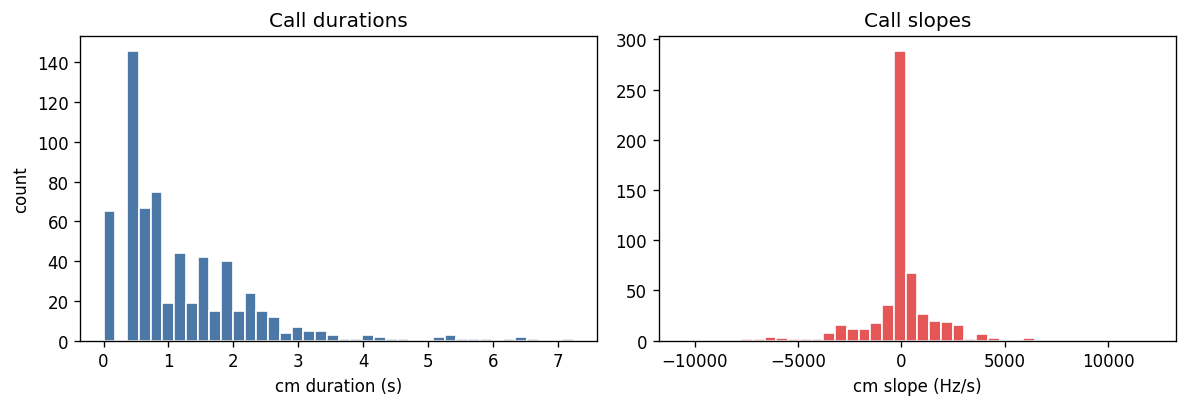

,start_time,end_time,boundary_cross_flag,cm_duration_sec,cm_duration_bin,cm_slope,cm_slope_ci,cm_slope_y_int,cm_freq_bandwidth_hz,cm_freq_bandwidth_bin,cm_start_freq_hz,cm_end_freq_hz,cm_min_freq_hz,cm_max_freq_hz,cm_abs_bandwidth_hz
209,146968513,148541376,0,7.24992,59.0,2.780687,0.043097,36.465636,97.656250,16.0,254.347656,236.037109,195.312500,NaN,92.552734
208,145616833,146968512,0,6.63552,54.0,-4.240756,0.066528,45.008352,177.001953,29.0,293.681424,254.347656,207.519531,NaN,287.865234
2,1548289,3047424,0,6.51264,53.0,-60.635103,0.241825,112.484443,689.697266,113.0,641.920898,144.484375,128.173828,NaN,2759.789062
17,12951553,14966784,1,6.38976,52.0,39.750440,0.120509,50.580464,500.488281,82.0,309.279297,657.179688,115.966797,NaN,1496.361328
143,95332993,97151616,0,6.26688,51.0,-33.104515,0.346886,125.960651,256.347656,42.0,770.094727,532.057617,500.488281,NaN,1069.115234
215,154374529,155849088,0,5.89824,48.0,-53.934067,0.219389,98.963983,463.867188,76.0,632.765625,181.105469,152.587891,NaN,934.837891
14,10051585,11476992,0,5.77536,47.0,-96.701641,0.766823,137.337618,708.007812,116.0,669.386719,232.985352,115.966797,NaN,3156.517578
635,442397377,443871936,0,5.52960,45.0,-81.939557,0.676467,129.790875,628.662109,103.0,602.248047,284.865234,225.830078,NaN,3589.867188
151,101206657,102288000,0,5.40672,44.0,6.546561,0.080304,73.583492,225.830078,37.0,385.573242,483.229492,323.486328,NaN,629.662109
435,307495681,308822784,0,5.40672,44.0,-1.393252,0.051882,49.446295,97.656250,16.0,269.606445,318.434570,244.140625,NaN,92.552734


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(csv["cm_duration_sec"].dropna(), bins=40, color="#4c78a8", edgecolor="white")
axes[0].set_xlabel("cm duration (s)")
axes[0].set_ylabel("count")
axes[0].set_title("Call durations")
axes[1].hist(csv["cm_slope"].dropna(), bins=40, color="#e45756", edgecolor="white")
axes[1].set_xlabel("cm slope (Hz/s)")
axes[1].set_title("Call slopes")
fig.tight_layout()
plt.show()

measure_cols = [
    c
    for c in csv.columns
    if c.startswith(("cm_", "cm_max_", "filter_")) or c in ("spec_noise", "spec_rl")
]
top = csv.sort_values("cm_duration_sec", ascending=False).head(12)
top[["start_time", "end_time", "boundary_cross_flag", *measure_cols[:12]]]

## Contours on active 15-second stretches

Find 15 s intervals with the most GPL detection time (activity), then plot each stretch with jet (full intensity range) over **0–500 Hz**. Overlay contours as a **bold yellow line** (ridge of `cm`, else `cm_max`), the **green line** approximation from each contour's bounding box and `slope` (Hz/s), and each detection's **start/end with white vertical lines**.


In [4]:
STRETCH_SEC = 15.0
N_STRETCHES = 8
FREQ_PLOT_LO = 0.0
FREQ_PLOT_HI = 500.0


def find_window_for_sample(sample: int) -> dict:
    for w in windows:
        if w["start_sample"] - 1 <= sample < w["end_sample"]:
            return w
    raise KeyError(f"no window for sample {sample}")


def call_column_start(call: dict, window: dict) -> int:
    return int(round((int(call["start_time"]) - (window["start_sample"] - 1)) / window["hop"]))


def freq_axis(n_rows: int, freq_lo: float, freq_hi: float) -> np.ndarray:
    return np.linspace(freq_lo, freq_hi, n_rows)


def active_stretches(n: int = N_STRETCHES) -> list[tuple[float, float, float]]:
    """Return (t0_sec, t1_sec, activity_sec) for the busiest non-overlapping stretches."""
    sr = windows[0]["sample_freq"]
    file_end = max(int(c["end_time"]) for c in calls) / sr
    edges = np.arange(0.0, file_end + STRETCH_SEC, STRETCH_SEC)
    scores = np.zeros(max(len(edges) - 1, 0), dtype=float)
    for c in calls:
        a, b = int(c["start_time"]) / sr, int(c["end_time"]) / sr
        i0 = int(a // STRETCH_SEC)
        i1 = int(min(b, file_end) // STRETCH_SEC)
        for i in range(max(i0, 0), min(i1, len(scores) - 1) + 1):
            lo, hi = edges[i], edges[i] + STRETCH_SEC
            scores[i] += max(0.0, min(b, hi) - max(a, lo))
    order = np.argsort(-scores)
    picked: list[tuple[float, float, float]] = []
    used: list[tuple[float, float]] = []
    for i in order:
        if scores[i] <= 0:
            break
        t0, t1 = float(edges[i]), float(edges[i] + STRETCH_SEC)
        if any(not (t1 <= u0 or t0 >= u1) for u0, u1 in used):
            continue
        picked.append((t0, t1, float(scores[i])))
        used.append((t0, t1))
        if len(picked) >= n:
            break
    return picked


def plot_stretch(t0: float, t1: float, activity: float) -> None:
    sr = windows[0]["sample_freq"]
    s0, s1 = int(t0 * sr), int(t1 * sr)
    window = find_window_for_sample((s0 + s1) // 2)
    hop = window["hop"]
    sp = np.load(window["path"]).astype(np.float64)
    n_freq, n_time = sp.shape
    freqs = freq_axis(n_freq, window["freq_lo"], window["freq_hi"])
    fmask = (freqs >= FREQ_PLOT_LO) & (freqs <= FREQ_PLOT_HI)
    if not np.any(fmask):
        print(f"skip stretch {t0:.1f}-{t1:.1f}s: no bins in {FREQ_PLOT_LO}-{FREQ_PLOT_HI} Hz")
        return
    freqs_plot = freqs[fmask]

    c0 = max(0, int(round((s0 - (window["start_sample"] - 1)) / hop)))
    c1 = min(n_time, int(round((s1 - (window["start_sample"] - 1)) / hop)))
    if c1 <= c0:
        print(f"skip empty stretch {t0:.1f}-{t1:.1f}s")
        return
    patch = sp[fmask][:, c0:c1]
    pt0 = (window["start_sample"] - 1 + c0 * hop) / sr
    pt1 = (window["start_sample"] - 1 + c1 * hop) / sr

    fig, ax = plt.subplots(figsize=(11, 4.0))
    im = ax.imshow(
        patch,
        origin="lower",
        aspect="auto",
        cmap="jet",
        vmin=float(np.min(patch)),
        vmax=float(np.max(patch)),
        extent=[pt0, pt1, freqs_plot[0], freqs_plot[-1]],
        interpolation="nearest",
    )
    plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02, label="whitened intensity")

    def contour_ridge(contour: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Per-column peak-frequency row of a sparse contour (empty cols dropped)."""
        cols = []
        rows = []
        for j in range(contour.shape[1]):
            col = contour[:, j]
            if not np.any(col > 0):
                continue
            cols.append(j)
            rows.append(int(np.argmax(col)))
        return np.asarray(cols, dtype=int), np.asarray(rows, dtype=int)

    def clip_line_to_box(
        t_a: float, t_b: float, f_lo: float, f_hi: float, slope_hz_s: float
    ) -> tuple[tuple[float, float], tuple[float, float]] | None:
        """Line through box center with slope ``slope_hz_s``, clipped to [t_a, t_b] x [f_lo, f_hi]."""
        if not (np.isfinite(slope_hz_s) and np.isfinite(f_lo) and np.isfinite(f_hi)):
            return None
        if t_b <= t_a or f_hi < f_lo:
            return None
        t_mid = 0.5 * (t_a + t_b)
        f_mid = 0.5 * (f_lo + f_hi)
        if abs(slope_hz_s) < 1e-12:
            return (t_a, t_b), (f_mid, f_mid)
        t_f_lo = t_mid + (f_lo - f_mid) / slope_hz_s
        t_f_hi = t_mid + (f_hi - f_mid) / slope_hz_s
        t0_c = max(t_a, min(t_f_lo, t_f_hi))
        t1_c = min(t_b, max(t_f_lo, t_f_hi))
        if t1_c <= t0_c:
            return None
        f0_c = f_mid + slope_hz_s * (t0_c - t_mid)
        f1_c = f_mid + slope_hz_s * (t1_c - t_mid)
        return (t0_c, t1_c), (f0_c, f1_c)

    n_over = 0
    labeled = False
    labeled_approx = False
    n_bounds = 0
    for call in calls:
        if int(call["end_time"]) <= s0 or int(call["start_time"]) >= s1:
            continue
        # Detection time bounds (white vertical lines).
        t_start = int(call["start_time"]) / sr
        t_end = int(call["end_time"]) / sr
        ax.axvline(t_start, color="white", lw=1.2, alpha=0.9, zorder=4,
                   label="detection start/end" if n_bounds == 0 else None)
        ax.axvline(t_end, color="white", lw=1.2, alpha=0.9, zorder=4)
        n_bounds += 1

        col_call = call_column_start(call, window)
        cname = None
        contour = None
        for name in ("cm", "cm_max"):
            if name in call:
                cname = name
                contour = from_sparse(call[name])
                break
        if contour is None or cname is None:
            continue
        xs, ys = contour_ridge(contour)
        if xs.size == 0:
            continue
        abs_cols = col_call + xs
        keep = (abs_cols >= c0) & (abs_cols < c1) & fmask[np.clip(ys, 0, len(fmask) - 1)]
        if not np.any(keep):
            continue
        t_line = (window["start_sample"] - 1 + abs_cols[keep] * hop) / sr
        f_line = freqs[np.clip(ys[keep], 0, len(freqs) - 1)]
        ax.plot(
            t_line,
            f_line,
            color="yellow",
            lw=3.5,
            solid_capstyle="round",
            label="contour" if not labeled else None,
            zorder=5,
        )
        labeled = True
        n_over += 1

        # Linear approximation from contour bounding box + slope (green line).
        m = call[cname]
        t_box0 = (window["start_sample"] - 1 + (col_call + int(xs[0])) * hop) / sr
        t_box1 = (window["start_sample"] - 1 + (col_call + int(xs[-1])) * hop) / sr
        seg = clip_line_to_box(
            t_box0,
            t_box1,
            float(m.get("min_freq_hz", float("nan"))),
            float(m.get("max_freq_hz", float("nan"))),
            float(m.get("slope", float("nan"))),
        )
        if seg is not None:
            (ta, tb), (fa, fb) = seg
            ax.plot(
                [ta, tb],
                [fa, fb],
                color="lime",
                lw=2.5,
                solid_capstyle="round",
                label="box + slope approx" if not labeled_approx else None,
                zorder=6,
            )
            labeled_approx = True

    ax.set_xlim(pt0, pt1)
    ax.set_ylim(FREQ_PLOT_LO, FREQ_PLOT_HI)
    ax.set_title(
        f"{pt0:.1f}–{pt1:.1f} s  |  {FREQ_PLOT_LO:.0f}–{FREQ_PLOT_HI:.0f} Hz  "
        f"(detection activity={activity:.2f} s, {n_over} contours, {n_bounds} detections)"
    )
    ax.set_xlabel("time in file (s)")
    ax.set_ylabel("frequency (Hz)")
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, loc="upper right")
    fig.tight_layout()
    plt.show()


stretches = active_stretches()
print(f"active {STRETCH_SEC:.0f} s stretches (t0, t1, activity_s):")
for row in stretches:
    print(f"  {row[0]:7.1f}–{row[1]:7.1f}  activity={row[2]:.2f}s")


active 15 s stretches (t0, t1, activity_s):
    720.0–  735.0  activity=13.43s
    735.0–  750.0  activity=12.87s
   1560.0– 1575.0  activity=12.50s
   1635.0– 1650.0  activity=12.50s
    765.0–  780.0  activity=12.29s
    750.0–  765.0  activity=12.17s
    975.0–  990.0  activity=12.17s
      0.0–   15.0  activity=12.05s


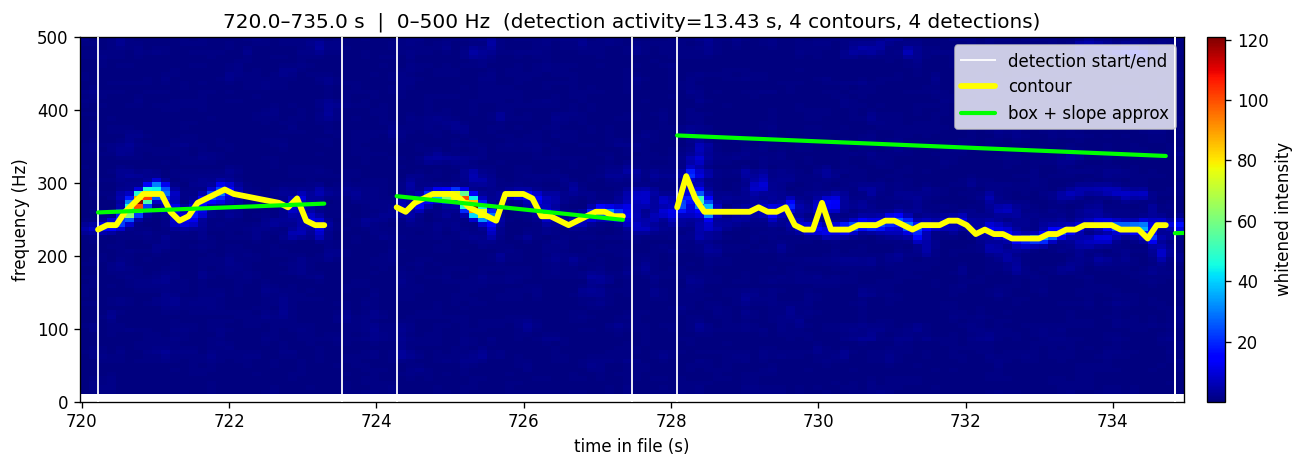

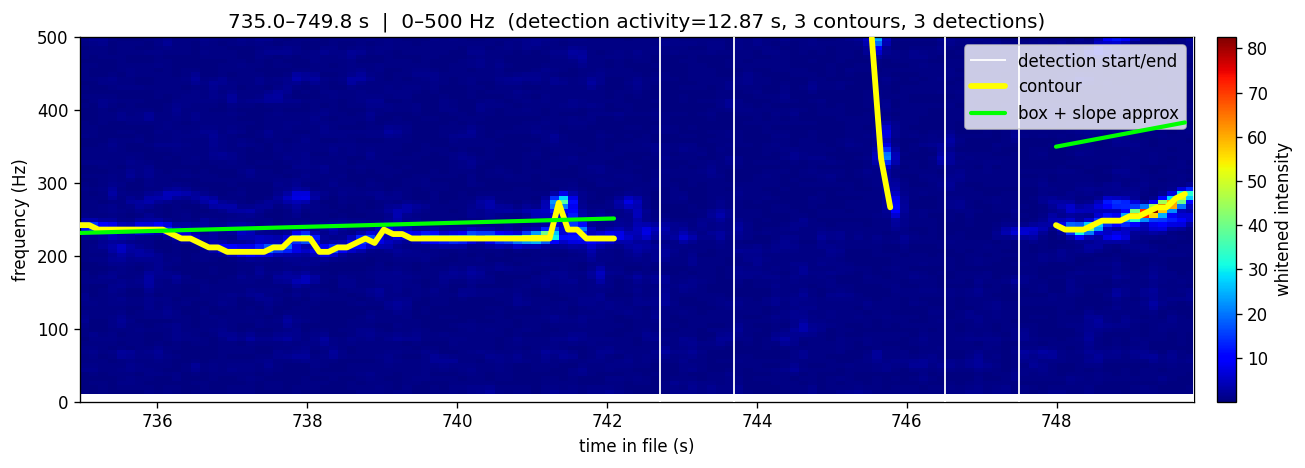

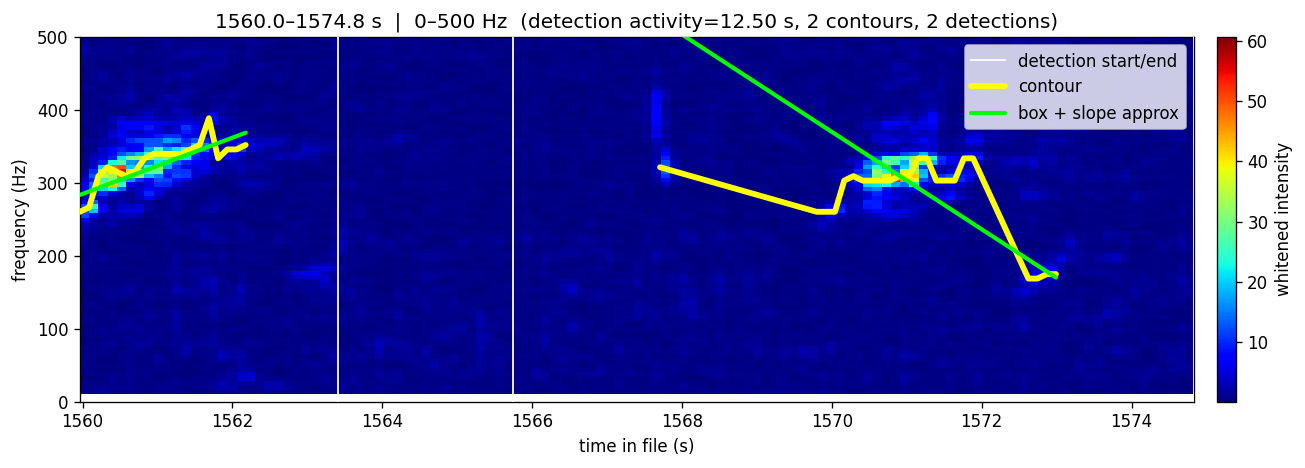

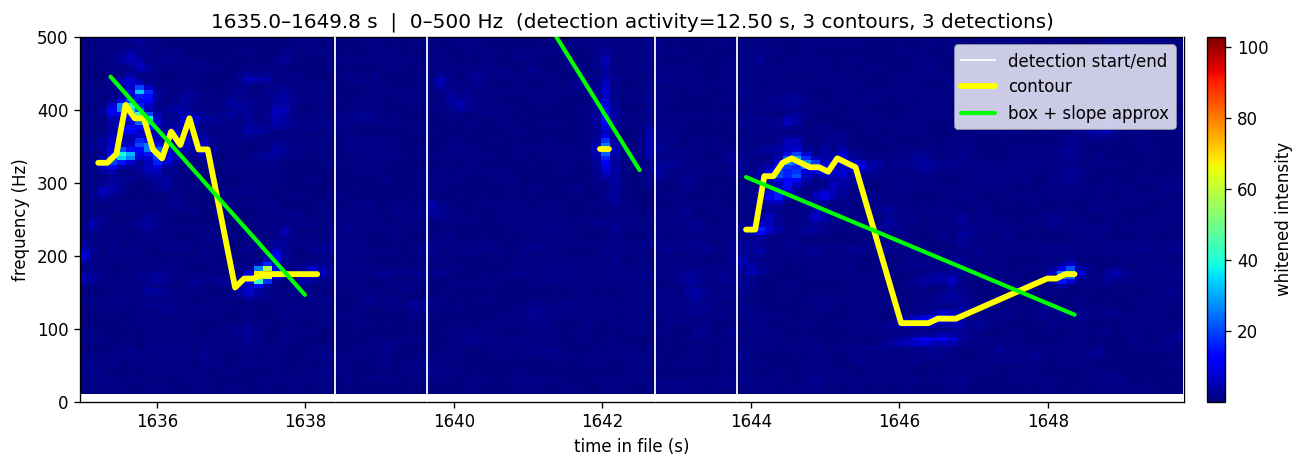

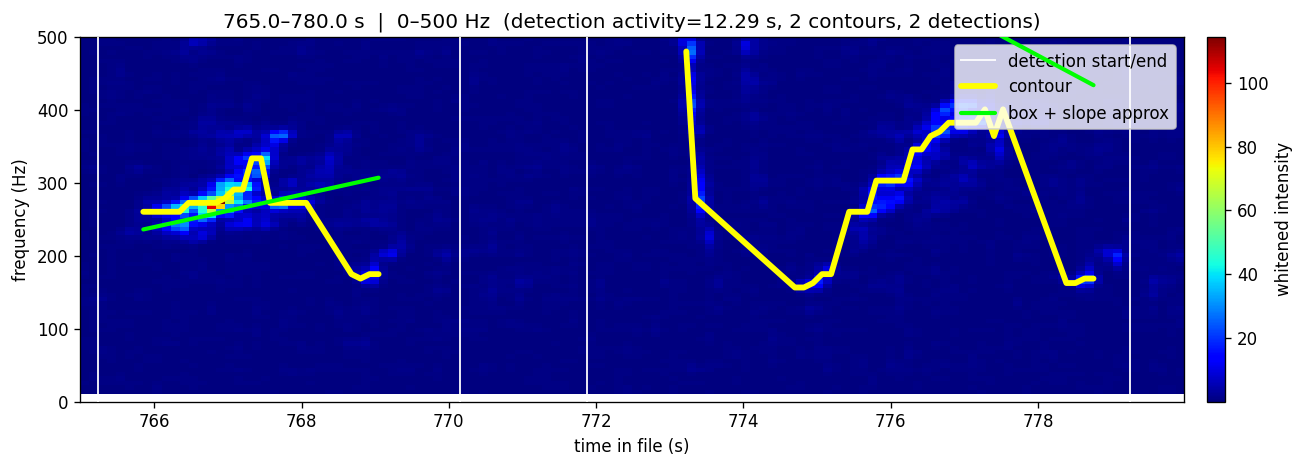

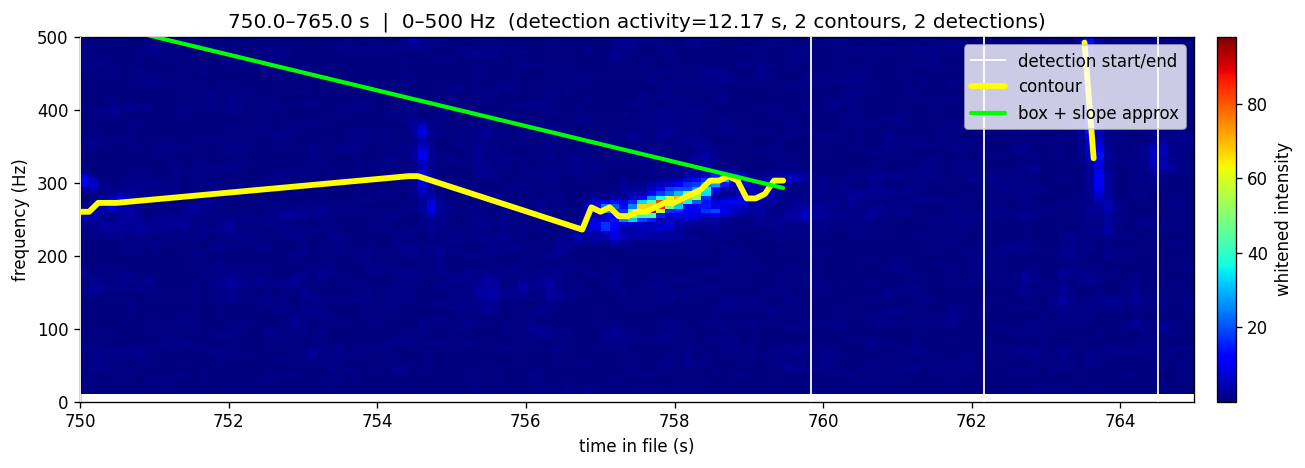

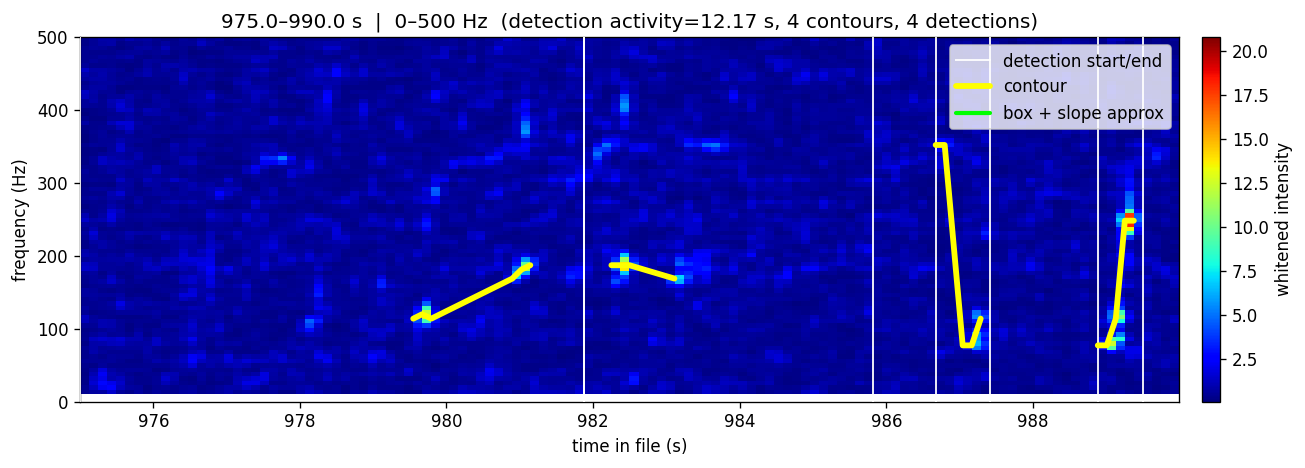

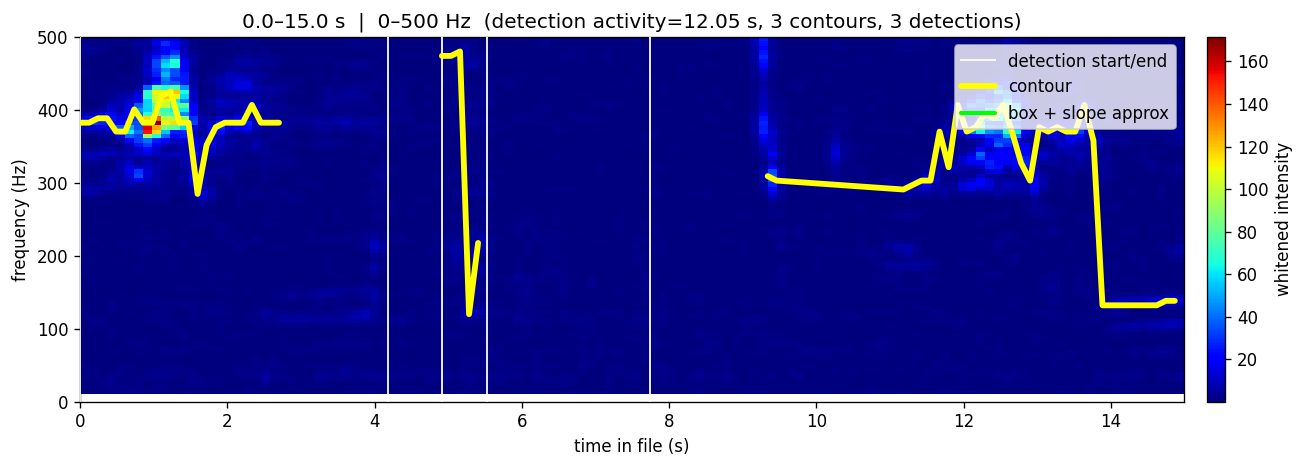

In [5]:
for t0, t1, activity in stretches:
    plot_stretch(t0, t1, activity)
